# Pilot Study: Sizing the Surrogate-Connectome Comparison (Study 3)

Compares 2 source-reconstruction methods (`wCSET`, `CSET`) across 6 connectome
*construction methods* used as the harmonic-prior source, instead of 6 reconstruction
methods at one connectome like the original pilot. Same design logic otherwise: one
simulated ground truth per `(region, repetition)`, reconstructed under every
`(method, surrogate)` combination, mixed-effects model to extract variance components,
Monte Carlo power/precision curves across a `(k regions, r repetitions)` grid.

**No new simulation needed.** Surrogates only change which connectome `wCSET`/`CSET`
use as their harmonic-prior source at reconstruction time -- they don't change what
ground truth gets simulated. This reuses the original 6-method pilot's simulated
dataset directly (`sub-simf10-pilot`: 26 regions x 8 repetitions x SNR=10, 208 runs,
still on disk under `data/derivatives/simulation/` even though that pilot's own
*analysis*-stage files were cleaned up) -- so there's no `pilot_surrogate_01_generate.py`
at all, just a solve step and this analysis.

**Surrogates** (6, matching `connectome_surrogates.ipynb`'s recipe plus one new one --
see `connectome_surrogates_plan.md` next to that notebook for the empirical
verification behind `fused`/`geom_atlas`'s parameters):
- `true` -- the empirical connectome
- `fused` / `fused_bin` -- atlas upscaling + geometric gap-fill (weighted / binarized)
- `geom_atlas` / `geom_atlas_bin` -- geometry-only, atlas params, geodesic-distance KNN
  with homotopic interhemispheric mirroring (weighted / binarized)
- `euclid` -- new: same KNN sparsification as `geom_atlas` but built from raw 3D
  Euclidean distance instead of mesh-geodesic distance (`connectome_from_euclidean_distance`,
  `mindmap/analysis/connectivity/process.py`) -- no binary variant (would make 7, not 6)

**Design**: `2 methods x 6 surrogates = 12` conditions per run, fit as **one** model
(unlike the noise-sweep pilot, there's no secondary sweep axis to fit separately per
level here -- `condition` already captures the full cross of method x surrogate).
Same well-identified `re_formula="~1"` + named `vc_formula` form as the original pilot,
just `fixed_col="condition"` with 12 levels instead of `fixed_col="method"` with 6.

**Companion script** (only the solve step -- no generation step needed):
- `pilot_surrogate_02_solve.py` -- builds the 6 surrogates + eigenspectra once upfront,
  then solves all 208 existing runs under all 12 conditions, checkpointed

## 🧬 - Running the pilot (run separately first)

`pilot_surrogate_02_solve.py` builds the 6 surrogate connectomes and their
eigenspectra once (data-integrity-checked against the known
`con`/`eig`/`Simulator` staleness trap first), then solves all 208 existing
`sub-simf10-pilot` runs under `wCSET`/`CSET` x all 6 connectomes -- same
`build_phase_data_hrp_pp_curve`/`score_source_reconstruction` scoring as the
other pilots, with each checkpoint row tagged `condition` (e.g. `"wcset_true"`,
`"cset_euclid"`) instead of `method`. Checkpointed per run
(`pilot_surrogate_metrics/run-{run:03d}.json` + `_curves.npz`), same
crash-recovery behavior as the other pilots' solve scripts.

Run it before executing the cells below.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import mindmap as mm

dm = mm.io.TutoManager("../../config.yml")
sub_pilot = "simf10-pilot"

METRICS_DIR = Path("pilot_surrogate_metrics")
OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
METHODS = ["wcset", "cset"]
SURROGATES = ["true", "fused", "fused_bin", "geom_atlas", "geom_atlas_bin", "euclid"]
CONDITIONS = [f"{m}_{s}" for m in METHODS for s in SURROGATES]
M = len(CONDITIONS)

## 📊 - Aggregate outcome measures

Same three outcome measures per `(region, repetition, condition)` as the original
pilot. `condition` is already a column in each checkpoint row (tagged by
`pilot_surrogate_02_solve.py`), so `load_pilot_checkpoints` only needs to pull
`region`/`repetition` from the run index.

In [2]:
df_index = pd.read_csv(dm.roots["sim"] / f"sub-{sub_pilot}" / "simulation_index.tsv", sep="\t")

df = mm.analysis.power.load_pilot_checkpoints(df_index, METRICS_DIR, index_cols=("region", "repetition"))
print(f"Aggregated {len(df)} (region,repetition,condition) rows "
      f"({df['run'].nunique()} runs x {df['condition'].nunique()} conditions).")
df.to_csv("pilot_surrogate_outcomes.tsv", sep="\t", index=False)
df.head()

Aggregated 2496 (region,repetition,condition) rows (208 runs x 12 conditions).


,run,condition,localization_error_hrp,ap_hrp,ap_pp,correlation_auc,region,repetition
0,1,wcset_true,0.000000,0.540026,0.930348,0.299989,ctx-rh-posteriorcingulate_2,1
1,1,cset_true,3.057148,0.626221,0.908363,0.367253,ctx-rh-posteriorcingulate_2,1
2,1,wcset_fused,2.224737,0.578679,0.933495,0.314196,ctx-rh-posteriorcingulate_2,1
3,1,cset_fused,0.000000,0.684632,0.917503,0.354748,ctx-rh-posteriorcingulate_2,1
4,1,wcset_fused_bin,4.610860,0.605575,0.934502,0.318476,ctx-rh-posteriorcingulate_2,1


## 📊 - Fit mixed-effects models, extract variance components

Same model as the original pilot -- `re_formula="~1"` (region random intercept) + named
variance components `condition_region` (`sigma2(condition x region)` -- does relative
performance across method x surrogate combinations depend on brain location, the effect
of primary scientific interest here) and `rep` (repetition-within-region) -- fit once
per outcome via the unmodified `fit_variance_components`, `fixed_col="condition"`
(12 levels) instead of `fixed_col="method"` (6 levels). Unlike the noise-sweep pilot,
there's no secondary factor to fit separately per level -- `condition` already is the
full method x surrogate cross.

In [3]:
variance_components = {}

for outcome in OUTCOMES:
    vc = mm.analysis.power.fit_variance_components(
        df, outcome,
        group_col="region", fixed_col="condition",
        vc_formula={"condition_region": "0 + C(condition)", "rep": "0 + C(repetition)"},
        fixed_levels=CONDITIONS,
    )
    variance_components[outcome] = {
        "sigma2_region": vc["sigma2_region"],
        "sigma2_condition_region": vc["sigma2_condition_region"],
        "sigma2_rep": vc["sigma2_rep"],
        "sigma2_resid": vc["sigma2_resid"],
        "condition_means": vc["condition_means"],
    }

with open("pilot_surrogate_variance_components.json", "w") as f:
    json.dump(variance_components, f, indent=2)

pd.DataFrame(variance_components).T[["sigma2_region", "sigma2_condition_region", "sigma2_rep", "sigma2_resid"]]

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,sigma2_region,sigma2_condition_region,sigma2_rep,sigma2_resid
localization_error_hrp,55.358086,52.191439,34.342067,189.090188
ap_hrp,0.016965,0.000763,0.000987,0.001013
ap_pp,0.009117,0.000229,0.000261,0.000177
correlation_auc,0.002479,0.001177,0.000109,0.0001


## 🎯 - Simulate power/precision curves across a `(k, r)` grid

Same Monte Carlo split-plot ANOVA as the original pilot
(`mindmap.core.power.simulate_splitplot_power`, region x condition, `r` sub-replicates
per cell), `m=12` conditions.

In [4]:
N_SIM = 2000
ALPHA = 0.05
k_grid = [10, 15, 20, 26, 35, 50, 75, 100]
r_grid = [3, 5, 8, 10, 15, 20]

power_results = {o: {"condition": np.zeros((len(k_grid), len(r_grid))), "interaction": np.zeros((len(k_grid), len(r_grid)))} for o in OUTCOMES}
precision_results = {o: np.zeros(len(r_grid)) for o in OUTCOMES}

for oi, outcome in enumerate(OUTCOMES):
    vc = variance_components[outcome]
    for i, k in enumerate(k_grid):
        for j, r in enumerate(r_grid):
            seed = oi * 100_000 + i * 1000 + j
            pm, pi = mm.core.simulate_splitplot_power(
                condition_means=vc["condition_means"],
                sigma2_group=vc["sigma2_region"],
                sigma2_interaction=vc["sigma2_condition_region"],
                sigma2_rep=vc["sigma2_rep"],
                sigma2_resid=vc["sigma2_resid"],
                k=k, r=r, m=M, n_sim=N_SIM, alpha=ALPHA, seed=seed,
            )
            power_results[outcome]["condition"][i, j] = pm
            power_results[outcome]["interaction"][i, j] = pi
    for j, r in enumerate(r_grid):
        precision_results[outcome][j] = mm.core.precision_of_mean(vc["sigma2_rep"], vc["sigma2_resid"], r, M)
    print(f"Power grid done for {outcome}")

np.savez("pilot_surrogate_power_results.npz", k_grid=k_grid, r_grid=r_grid,
         **{f"{o}_condition": power_results[o]["condition"] for o in OUTCOMES},
         **{f"{o}_interaction": power_results[o]["interaction"] for o in OUTCOMES},
         **{f"{o}_precision": precision_results[o] for o in OUTCOMES})

Power grid done for localization_error_hrp


Power grid done for ap_hrp


Power grid done for ap_pp


Power grid done for correlation_auc


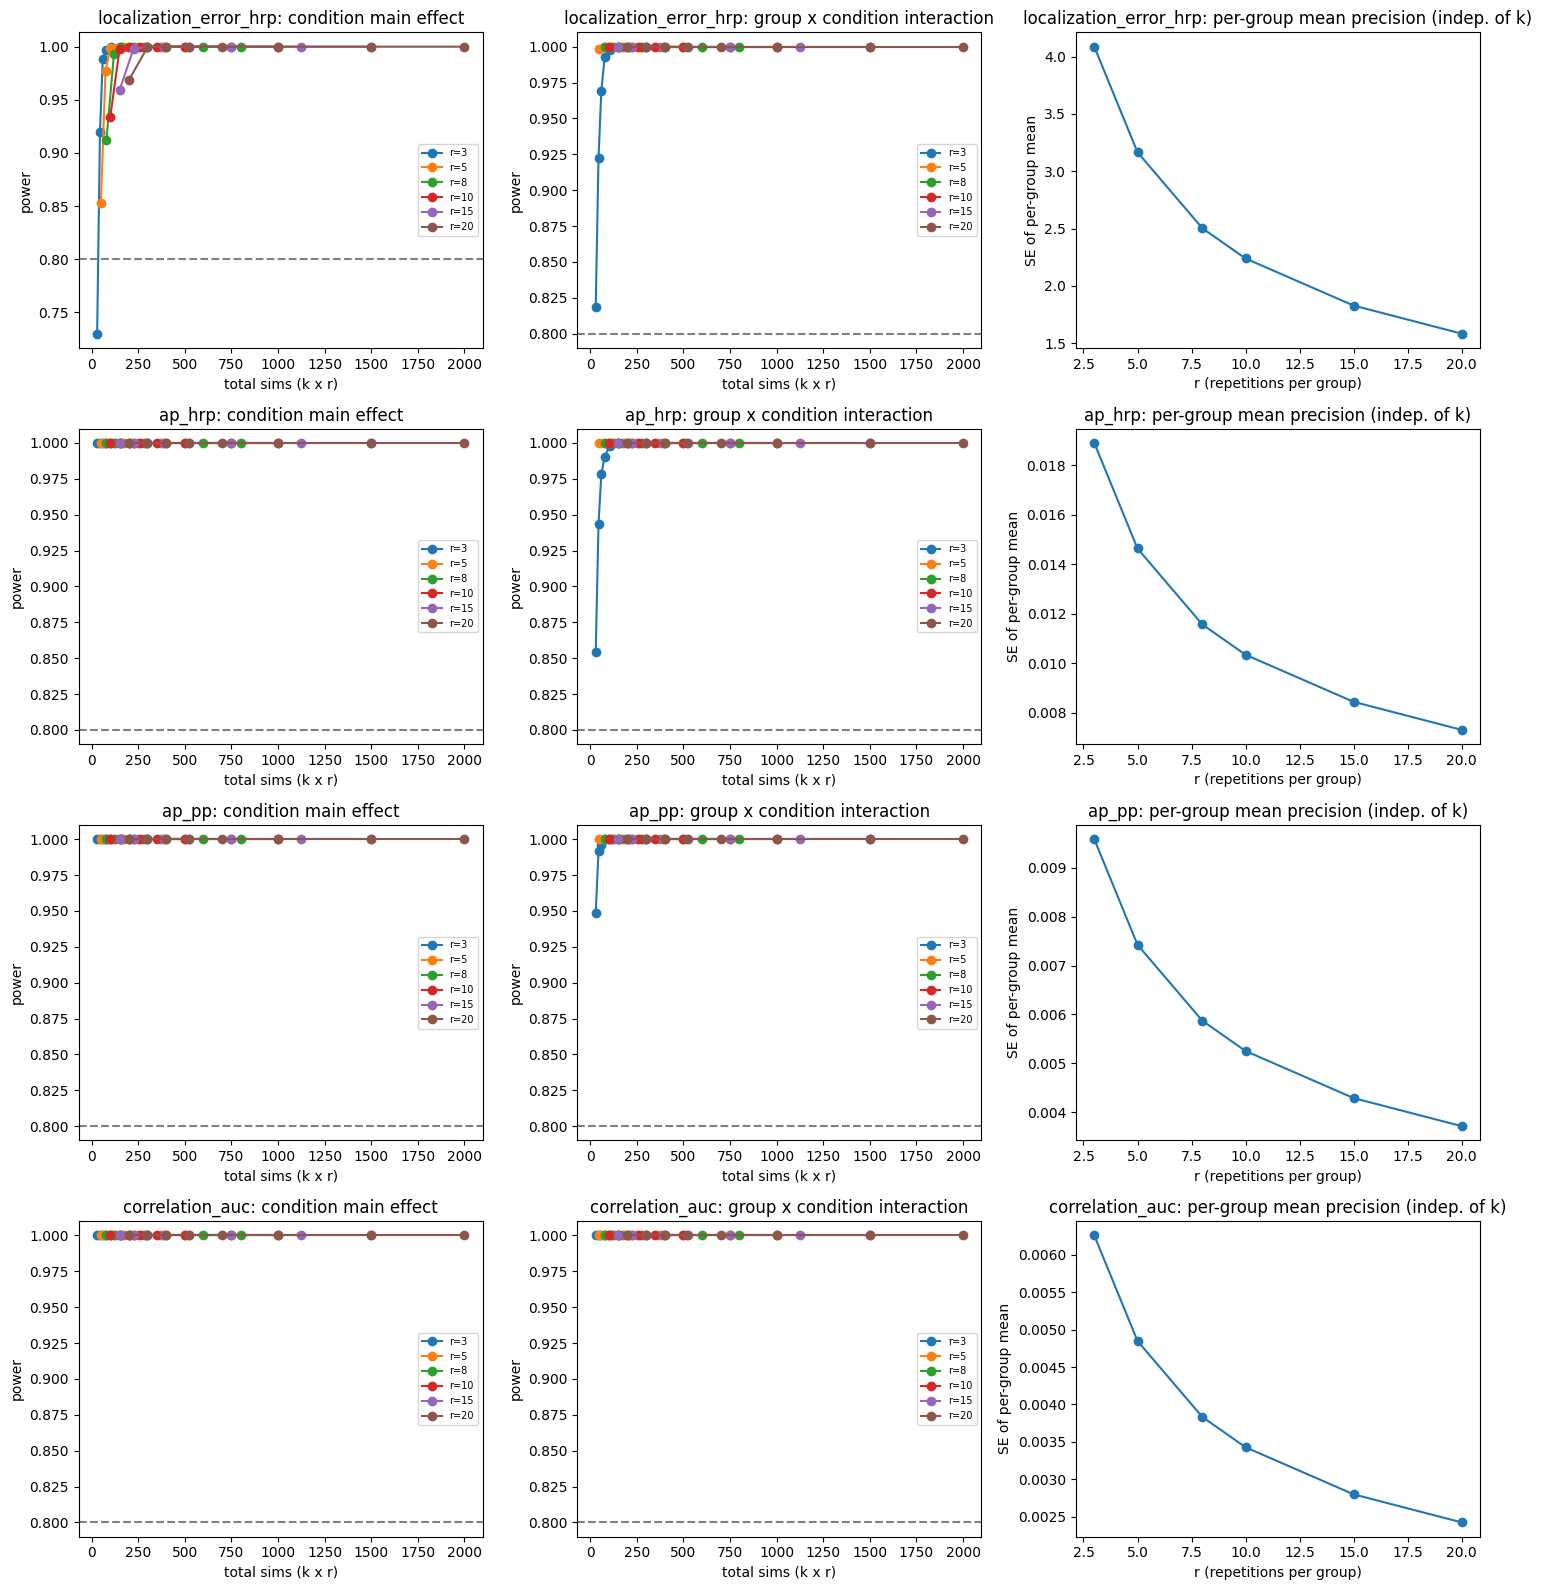

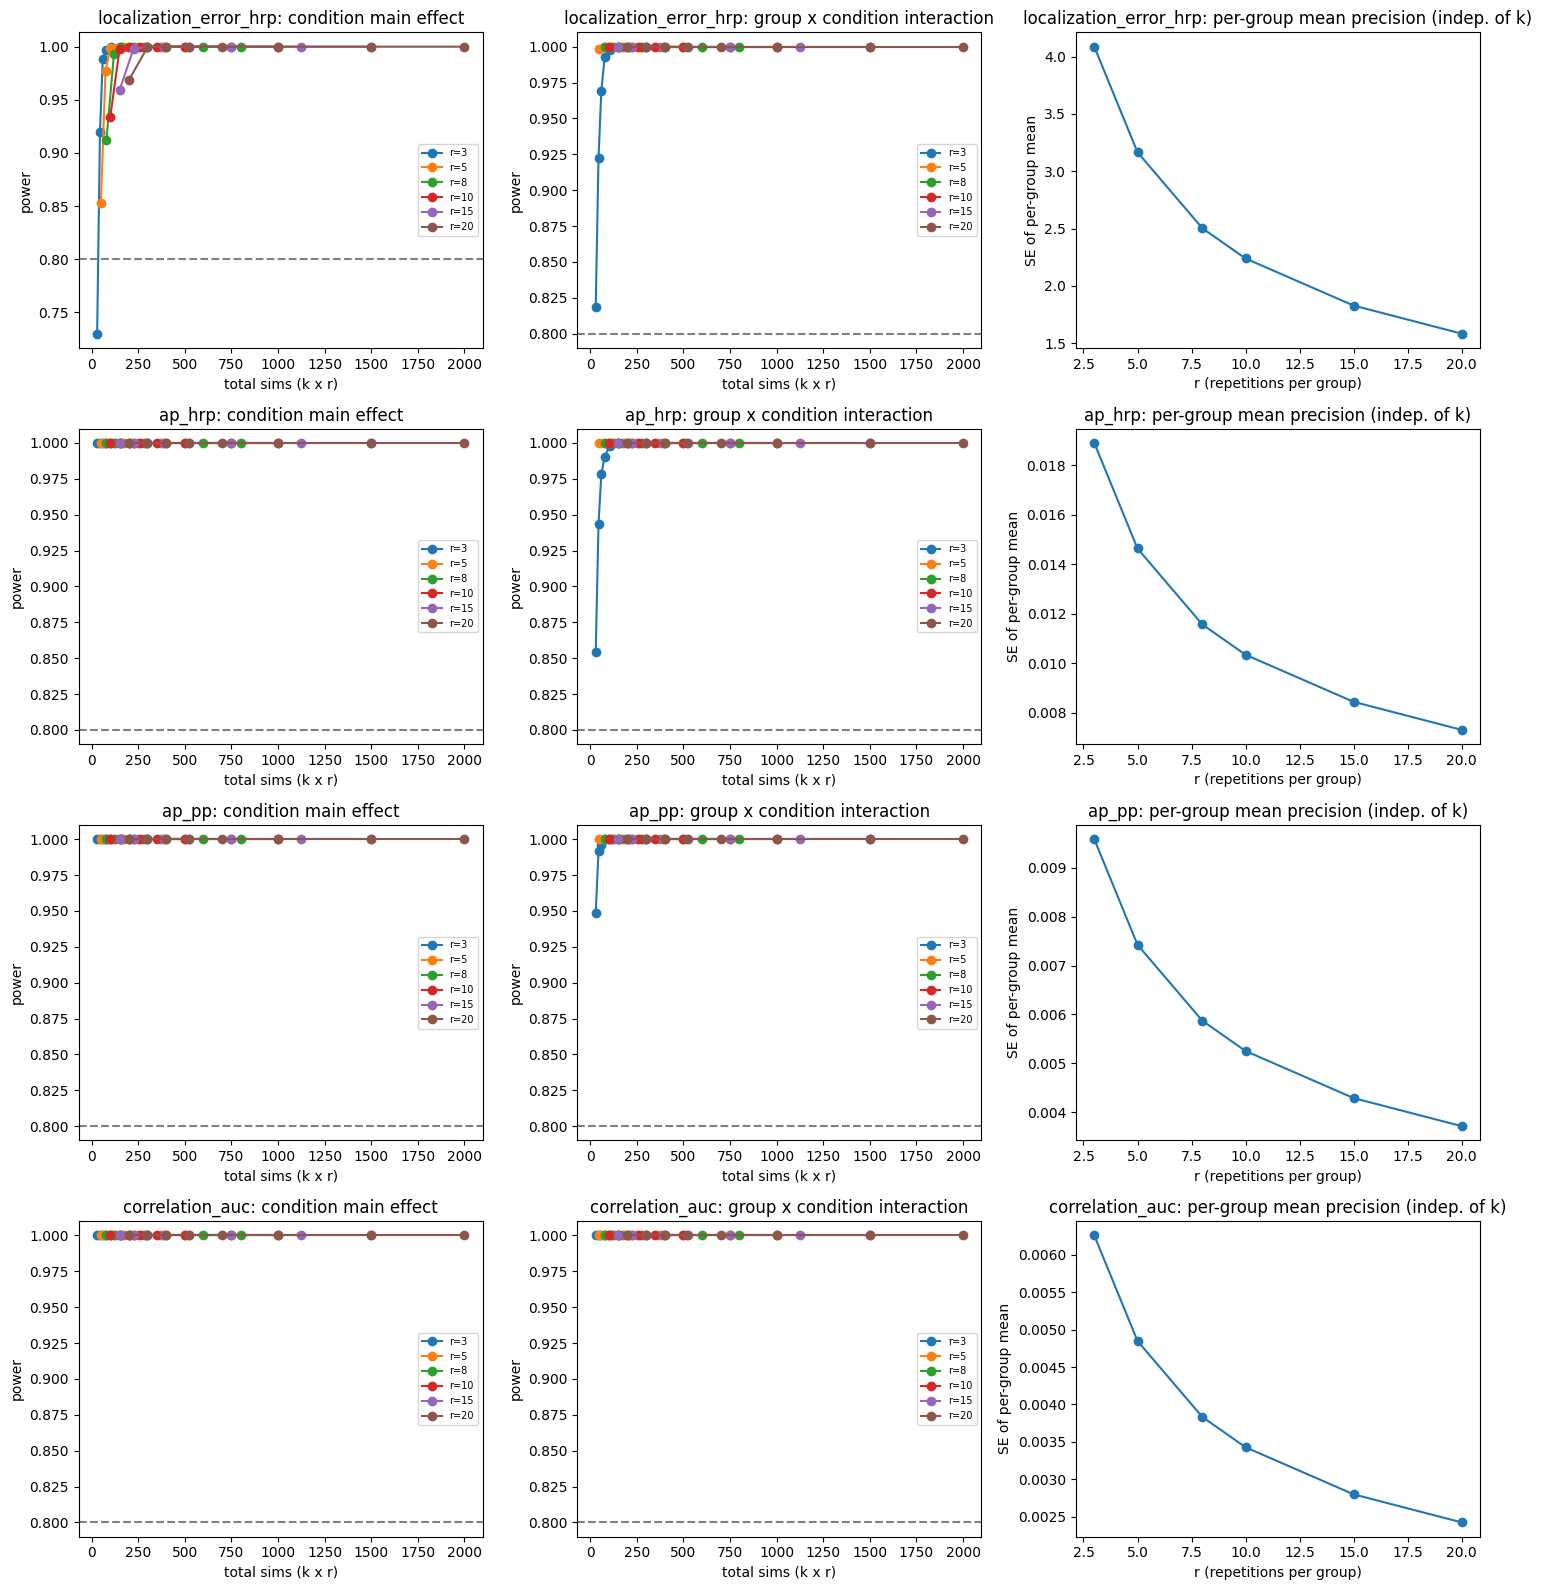

In [5]:
fig = mm.viz.plot_power_precision_curves(power_results, precision_results, k_grid, r_grid, OUTCOMES)
fig.savefig("pilot_surrogate_power_curves.png", dpi=130)
fig

## ✅ - Recommendation

Sized to the worst `(outcome, test)` combination across the grid -- same "size to the
hardest case" principle as the original pilot. Checked separately for the condition
main effect and the `condition x region` interaction, since the original pilot found
the main effect saturated near 1.0 everywhere while the interaction test was the actual
binding constraint -- worth re-verifying here rather than assuming, since a 12-level
factor spanning two methods and six surrogates is a much less homogeneous set of
conditions than the original's 6 same-purpose reconstruction methods.

In [6]:
def worst_case_power(power_results, test):
    worst = np.ones((len(k_grid), len(r_grid)))
    for outcome in OUTCOMES:
        worst = np.minimum(worst, power_results[outcome][test])
    return worst

worst_condition = worst_case_power(power_results, "condition")
worst_interaction = worst_case_power(power_results, "interaction")

THRESHOLD = 0.8
for name, worst in [("condition (main effect)", worst_condition), ("interaction (condition x region)", worst_interaction)]:
    ok = worst >= THRESHOLD
    if not ok.any():
        print(f"{name}: no (k, r) in this grid reaches {THRESHOLD} power across every outcome -- extend the grid.")
        continue
    total_sims = np.array(k_grid)[:, None] * np.array(r_grid)[None, :]
    candidates = np.where(ok, total_sims, np.inf)
    i, j = np.unravel_index(np.argmin(candidates), candidates.shape)
    print(f"{name}: smallest design clearing {THRESHOLD} power everywhere -- "
          f"k={k_grid[i]} regions, r={r_grid[j]} repetitions "
          f"(worst-case power={worst[i, j]:.3f}, total sims/condition={k_grid[i]*r_grid[j]}).")

condition (main effect): smallest design clearing 0.8 power everywhere -- k=15 regions, r=3 repetitions (worst-case power=0.919, total sims/condition=45).
interaction (condition x region): smallest design clearing 0.8 power everywhere -- k=10 regions, r=3 repetitions (worst-case power=0.819, total sims/condition=30).
